# Stage 1: retrieval sources

The first stage proposes up to 500 candidate tracks per user by merging five sources, each with a fixed quota (`QUOTA` in `yrec.retrieval`):

- **Two-tower** (`tt`): a learned user tower over the listening history and an item tower over ID, artist and audio embeddings.
- **ALS**: implicit-feedback matrix factorisation.
- **Audio profile** (`audio`): nearest tracks to the mean audio embedding of the user's history.
- **Popularity** (`pop`): the most played recent tracks.
- **Repeat history** (`repeat`): the user's own previously played tracks (all-listens view only).

Every source is evaluated on the test day in two views: **all** (every Listen+ track counts) and **discovery** (only tracks the user never played before the cutoff; history is excluded from the rankings). Recall@K and NDCG@K are averaged over users, Coverage@K is the share of the catalogue that appears in any user's top K.

In [1]:
import json, os, sys
from pathlib import Path

ROOT = Path('..')
os.environ.setdefault('DATA_DIR', str(ROOT / 'data'))
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
from yrec.data import PROC

RES, ART = ROOT / 'results', ROOT / 'artifacts'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b4b2ab', '#52514e'
plt.rcParams.update({
    'figure.figsize': (8, 4), 'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': INK,
    'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.grid': True, 'grid.color': '#e6e5e1',
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.grid.axis': 'y', 'legend.frameon': False, 'font.size': 10,
})
def save(fig, name):
    fig.savefig(FIG / f'{name}.png'); plt.show()

def load(path):
    """Parsed JSON, or None with a short note when the file has not been produced yet."""
    if not path.exists():
        print(f'{path.relative_to(ROOT)} not available yet; the dependent section is skipped.')
        return None
    return json.loads(path.read_text())

VIEWS = ('all', 'discovery')
VIEW_COLOR = {'all': BLUE, 'discovery': AQUA}
SRC = ('tt', 'als', 'audio', 'pop', 'repeat')
NAME = {'tt': 'Two-tower', 'als': 'ALS', 'audio': 'Audio profile', 'pop': 'Popularity', 'repeat': 'Repeat history'}
SRC_COLOR = {'tt': BLUE, 'als': ORANGE, 'audio': AQUA, 'pop': GREY, 'repeat': INK}
def fmt_table(df):
    """3 decimals for recall/NDCG, percent for coverage, en dash for missing."""
    f = {c: '{:.2%}' if 'coverage' in str(c) else '{:.3f}' for c in df.columns}
    return df.style.format(f, na_rep='–')
def bar_labels(ax, bars, vals, fmt='{:.3f}', fontsize=8):
    ax.bar_label(bars, labels=['' if pd.isna(v) else fmt.format(v) for v in vals], padding=2, color=INK, fontsize=fontsize)
notes = []  # one summary bullet per section, filled as sections run

## 1. Ranking quality of each source

Each source's own ordering, scored as if it were the final recommender (top 100 per user).

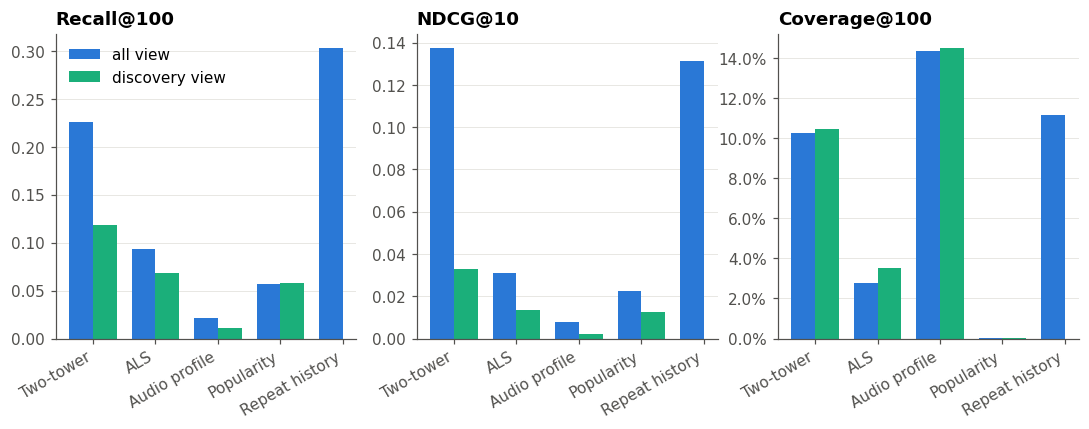

all view: best NDCG@10 from Two-tower (0.137), best Recall@100 from Repeat history (0.303), widest catalogue coverage@100 from Audio profile (14.39%).
discovery view: best NDCG@10 from Two-tower (0.033), best Recall@100 from Two-tower (0.119), widest catalogue coverage@100 from Audio profile (14.52%).


In [2]:
s1 = {v: load(RES / f'stage1_{v}.json') for v in VIEWS}
if not any(s1.values()):
    print('Stage-1 results not available yet; section skipped.')
else:
    MET = ['recall@100', 'ndcg@10', 'coverage@100']
    long = pd.DataFrame([dict(view=v, source=s, **{m: r[m] for m in MET})
                         for v, d in s1.items() if d for s, r in d['sources'].items()])
    srcs = [s for s in SRC if s in set(long.source)]
    tab = long.pivot(index='source', columns='view', values=MET).reindex(srcs).rename(index=NAME)
    display(fmt_table(tab))
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
    x, w = np.arange(len(srcs)), 0.38
    for ax, m in zip(axes, MET):
        for j, v in enumerate(VIEWS):
            vals = [tab.loc[NAME[s], (m, v)] if (m, v) in tab.columns else np.nan for s in srcs]
            ax.bar(x + (j - 0.5) * w, vals, w, color=VIEW_COLOR[v], label=f'{v} view')
        ax.set_xticks(x, [NAME[s] for s in srcs], rotation=30, ha='right'); ax.set_title(m.replace('recall', 'Recall').replace('ndcg', 'NDCG').replace('coverage', 'Coverage'))
        if m.startswith('coverage'): ax.yaxis.set_major_formatter(PercentFormatter(1))
    axes[0].legend(loc='upper left')
    save(fig, '10_source_metrics')
    for v, d in s1.items():
        if not d: continue
        r = pd.DataFrame(d['sources']).T
        msg = (f"{v} view: best NDCG@10 from {NAME[r['ndcg@10'].idxmax()]} ({r['ndcg@10'].max():.3f}), "
               f"best Recall@100 from {NAME[r['recall@100'].idxmax()]} ({r['recall@100'].max():.3f}), "
               f"widest catalogue coverage@100 from {NAME[r['coverage@100'].idxmax()]} ({r['coverage@100'].max():.2%}).")
        print(msg); notes.append(msg)

## 2. Candidate recall: each source versus the union

Candidate recall is the share of test-day target (user, track) pairs that appear anywhere in a candidate list, micro-averaged over pairs. Per-source values use that source's quota; the union is the merged list of at most 500 candidates and is the ceiling for any re-ranker.

,all,discovery
Two-tower,19.7%,14.8%
ALS,7.8%,7.3%
Audio profile,0.9%,0.9%
Popularity,1.4%,2.0%
Repeat history,29.3%,–
Union (<= 500),40.0%,20.3%


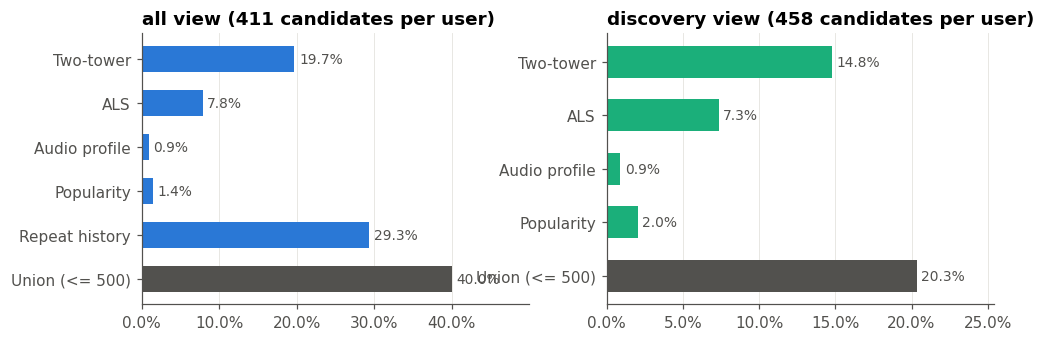

all view: the union reaches 40.0% candidate recall versus 29.3% for the best single source (Repeat history); per-source recalls sum to 59.2%, so overlap between sources is 19.2% of target pairs.
discovery view: the union reaches 20.3% candidate recall versus 14.8% for the best single source (Two-tower); per-source recalls sum to 25.1%, so overlap between sources is 4.7% of target pairs.


In [3]:
if not any(s1.values()):
    print('Stage-1 results not available yet; section skipped.')
else:
    cr = pd.DataFrame({v: {**{NAME[s]: d['source_candidate_recall'].get(s, np.nan) for s in SRC if s in d['source_candidate_recall']},
                           'Union (<= 500)': d['candidate_recall@500']} for v, d in s1.items() if d})
    display(cr.style.format('{:.1%}', na_rep='–'))
    fig, axes = plt.subplots(1, len(cr.columns), figsize=(5 * len(cr.columns), 3.2), squeeze=False)
    for ax, v in zip(axes[0], cr.columns):
        c = cr[v].dropna()
        colors = [INK if k.startswith('Union') else VIEW_COLOR[v] for k in c.index]
        b = ax.barh(c.index, c.values, color=colors, height=0.6)
        ax.bar_label(b, labels=[f'{x:.1%}' for x in c.values], padding=3, color=INK, fontsize=9)
        ax.invert_yaxis(); ax.grid(True, axis='x'); ax.grid(False, axis='y')
        ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlim(0, c.max() * 1.25)
        ax.set_title(f'{v} view ({s1[v]["candidates_per_user"]:.0f} candidates per user)')
    save(fig, '11_candidate_recall')
    for v in cr.columns:
        c = cr[v].drop('Union (<= 500)').dropna()
        msg = (f"{v} view: the union reaches {cr.loc['Union (<= 500)', v]:.1%} candidate recall versus {c.max():.1%} for the best "
               f"single source ({c.idxmax()}); per-source recalls sum to {c.sum():.1%}, so overlap between sources is "
               f"{c.sum() - cr.loc['Union (<= 500)', v]:.1%} of target pairs.")
        print(msg); notes.append(msg)

## 3. Candidate recall versus depth

From the candidate files, each source's 0-based rank (`<source>_rank`) gives the share of target pairs it would recover with only its top K candidates, for K up to the source's quota. The dashed line is the recall of the full union. The table also lists the share of union hits that only one source found, which is what each source adds beyond the others.

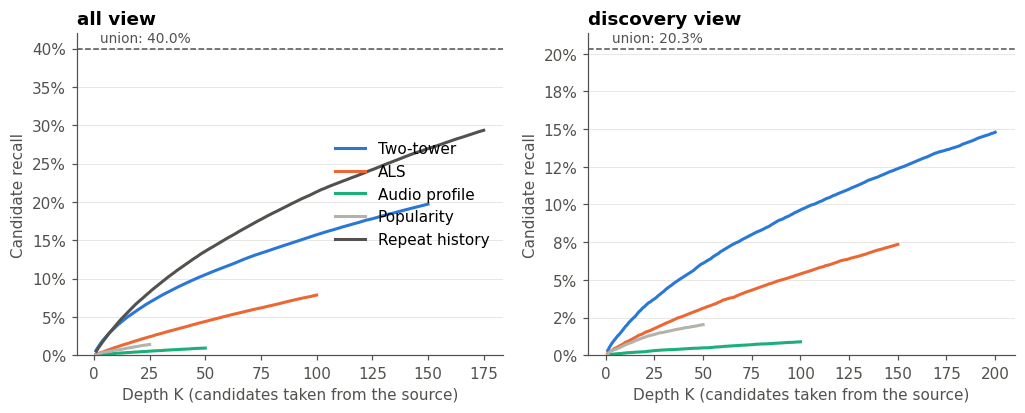

all view: Repeat history contributes the most unique hits (38.4% of the union's hits are found by it alone); 61.1% of hits come from exactly one source.
discovery view: Two-tower contributes the most unique hits (53.3% of the union's hits are found by it alone); 79.1% of hits come from exactly one source.


In [4]:
tgt_path = PROC / 'tgt_AB.parquet'
hits, n_tgt = {}, {}
if not tgt_path.exists():
    print(f'{tgt_path.relative_to(ROOT)} not available yet; section skipped.')
else:
    tg = pd.read_parquet(tgt_path, columns=['uidx', 'item_idx', 'lp', 'is_new'])
    for v in VIEWS:
        p = PROC / f'cand_AB_{v}.parquet'
        if not p.exists():
            print(f'{p.relative_to(ROOT)} not available yet; {v} view skipped.'); continue
        cand = pd.read_parquet(p)
        t = tg[tg.lp & tg.is_new] if v == 'discovery' else tg[tg.lp]
        n_tgt[v] = len(t)
        h = t.merge(cand, on=['uidx', 'item_idx'])
        quota = {s: int(cand[f'{s}_rank'].max()) + 1 for s in SRC if cand[f'{s}_rank'].notna().any()}
        hits[v] = (h, quota)
if hits:
    fig, axes = plt.subplots(1, len(hits), figsize=(5.5 * len(hits), 3.8), squeeze=False)
    rows = []
    for ax, (v, (h, quota)) in zip(axes[0], hits.items()):
        n_src = h[[f'{s}_rank' for s in quota]].notna().sum(1)
        for s, q in quota.items():
            r = np.sort(h[f'{s}_rank'].dropna().to_numpy())
            K = np.arange(1, q + 1)
            ax.plot(K, np.searchsorted(r, K) / n_tgt[v], color=SRC_COLOR[s], lw=2, label=NAME[s])
            only = (h[f'{s}_rank'].notna() & (n_src == 1)).sum()
            rows.append(dict(view=v, source=NAME[s], quota=q, **{'candidate recall at quota': len(r) / n_tgt[v],
                             'exclusive share of union hits': only / len(h)}))
        ax.axhline(len(h) / n_tgt[v], color=INK, ls='--', lw=1)
        ax.annotate(f'union: {len(h) / n_tgt[v]:.1%}', (0, len(h) / n_tgt[v]), xytext=(4, 4), textcoords='offset points', color=INK, fontsize=9)
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0)
        ax.set(xlabel='Depth K (candidates taken from the source)', ylabel='Candidate recall', title=f'{v} view')
    axes[0][0].legend(loc='center right')
    save(fig, '12_recall_vs_depth')
    dep = pd.DataFrame(rows).set_index(['view', 'source'])
    display(dep.style.format({'candidate recall at quota': '{:.1%}', 'exclusive share of union hits': '{:.1%}'}))
    for v in hits:
        d = dep.loc[v]
        msg = (f"{v} view: {d['exclusive share of union hits'].idxmax()} contributes the most unique hits "
               f"({d['exclusive share of union hits'].max():.1%} of the union's hits are found by it alone); "
               f"{d['exclusive share of union hits'].sum():.1%} of hits come from exactly one source.")
        print(msg); notes.append(msg)

## 4. Why repeat history dominates the all-listens view

Most Listen+ events are re-listens of tracks the user already knows, so in the **all** view a ranked list of the user's own history is a strong recommender and the repeat source receives the largest quota. In the **discovery** view every previously played track is excluded by definition, so the repeat source has nothing to contribute and is dropped; its quota is redistributed to the sources that can propose unseen tracks. The table splits the all-view targets by whether the track was in the user's history and shows which sources reach them.

In [5]:
if 'all' not in hits or 'repeat' not in hits['all'][1]:
    print('All-view candidates with a repeat source not available; section skipped.')
else:
    h, quota = hits['all']
    t = tg[tg.lp].merge(h[['uidx', 'item_idx'] + [f'{s}_rank' for s in quota]], how='left')
    other = t[[f'{s}_rank' for s in quota if s != 'repeat']].notna().any(axis=1)
    t = t.assign(target=np.where(t.is_new, 'New to the user', 'In the user history'),
                 by_repeat=t.repeat_rank.notna(), by_other=other)
    rep = t.groupby('target').agg(share_of_targets=('lp', 'size'), reached_by_repeat=('by_repeat', 'mean'),
                                  reached_by_other_sources=('by_other', 'mean'))
    rep['share_of_targets'] /= rep.share_of_targets.sum()
    display(rep.style.format('{:.1%}'))
    known = rep.loc['In the user history']
    msg = (f"{known.share_of_targets:.1%} of all-view Listen+ targets are tracks from the user history; repeat reaches "
           f"{known.reached_by_repeat:.1%} of them versus {known.reached_by_other_sources:.1%} for all other sources combined, "
           f"and repeat accounts for {h.repeat_rank.notna().mean():.1%} of all-view candidate hits.")
    print(msg); notes.append(msg)

,share_of_targets,reached_by_repeat,reached_by_other_sources
target,,,
In the user history,68.9%,42.6%,31.8%
New to the user,31.1%,0.0%,8.8%


68.9% of all-view Listen+ targets are tracks from the user history; repeat reaches 42.6% of them versus 31.8% for all other sources combined, and repeat accounts for 73.4% of all-view candidate hits.


## Summary

Bullet points below are computed from the result files in the cells above.

In [6]:
display(Markdown('\n'.join(f'- {n}' for n in notes) if notes else '- No result files were available when this notebook ran.'))

- all view: best NDCG@10 from Two-tower (0.137), best Recall@100 from Repeat history (0.303), widest catalogue coverage@100 from Audio profile (14.39%).
- discovery view: best NDCG@10 from Two-tower (0.033), best Recall@100 from Two-tower (0.119), widest catalogue coverage@100 from Audio profile (14.52%).
- all view: the union reaches 40.0% candidate recall versus 29.3% for the best single source (Repeat history); per-source recalls sum to 59.2%, so overlap between sources is 19.2% of target pairs.
- discovery view: the union reaches 20.3% candidate recall versus 14.8% for the best single source (Two-tower); per-source recalls sum to 25.1%, so overlap between sources is 4.7% of target pairs.
- all view: Repeat history contributes the most unique hits (38.4% of the union's hits are found by it alone); 61.1% of hits come from exactly one source.
- discovery view: Two-tower contributes the most unique hits (53.3% of the union's hits are found by it alone); 79.1% of hits come from exactly one source.
- 68.9% of all-view Listen+ targets are tracks from the user history; repeat reaches 42.6% of them versus 31.8% for all other sources combined, and repeat accounts for 73.4% of all-view candidate hits.